# Import the dataset 

In [77]:
#To install libraries
# !pip install numpy
# !pip install pandas
# !pip install matplotlib
# !pip install DateTime
# !pip install requests
# !pip install opencv-python
# !pip install Pillow
# !pip install Shapely
# !pip install seaborn
# !pip install opencv-python

In [1]:
#Change it to your name 
PERSONAL_OUTPUT = "howard"

##Configurable for each camera
ROUTE_DIR = "b_PIE"
CAMERA_ID = "2705"
# ROUTE_DIR = "aye_jurong"
# CAMERA_ID = "4702"
#only this is to modified for april 2022
GOOGLE_DIR = "march_google_2022"
CNN_DIR = "march_cnn_2022"
MONTH = "3"

### Environment variables

In [2]:
# !conda install seaborn
import pandas as pd
from io import BytesIO
import numpy as np
import cv2,os,requests

import warnings
warnings.filterwarnings('ignore')

from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
from PIL import Image,ImageDraw

BASE_DIR = os.getcwd()
INPUT_DIR = "input"
OUTPUT_CSV = "output_csv_transformer_test"
OUTPUT_IMG = "output_img_transformer_test"


CNN_FORMATTED = "masked_cnn"
COMBINED_DIR = "combined_cnn_google"
GOOGLE_FORMATED  ="google_speed"

print(BASE_DIR)
#input
INPUT_DIR_PATH = os.path.join(BASE_DIR , INPUT_DIR)
print("INPUT_DIR_PATH :: ", INPUT_DIR_PATH)

GOOGLE_PATH = os.path.join(INPUT_DIR_PATH , GOOGLE_DIR)
print("GOOGLE_PATH :: ", GOOGLE_PATH)

CNN_PATH =  os.path.join(INPUT_DIR_PATH , CNN_DIR)
print("CNN_PATH :: ", CNN_PATH)

ROUTE_PATH = os.path.join(GOOGLE_PATH , ROUTE_DIR)
print("ROUTE_DIR :: ", ROUTE_PATH)

GOOGLE_CAMERA_PATH = os.path.join(ROUTE_PATH , CAMERA_ID)
print("GOOGLE_CAMERA_PATH :: ", GOOGLE_CAMERA_PATH)

CNN_CAMERA_PATH = os.path.join(CNN_PATH , CAMERA_ID)
print("CNN_CAMERA_PATH :: ", CNN_CAMERA_PATH)

print()
##Output
OUTPUT_CSV_PATH = os.path.join(BASE_DIR , OUTPUT_CSV)

if not os.path.exists(OUTPUT_CSV_PATH):
    os.mkdir(OUTPUT_CSV_PATH)
print("OUTPUT_CSV_PATH :: ", OUTPUT_CSV_PATH)
        
OUTPUT_IMG_PATH = os.path.join(BASE_DIR , OUTPUT_IMG)
print("OUTPUT_IMG_PATH :: ", OUTPUT_IMG_PATH)

if not os.path.exists(OUTPUT_IMG_PATH):
    os.mkdir(OUTPUT_IMG_PATH)
    
    
#output configurable
MASKED_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+".jpg")
print("MASKED_IMG :: ",MASKED_IMG)


OUTPUT_ROUTE_PATH = os.path.join(OUTPUT_CSV_PATH , ROUTE_DIR)
print("OUTPUT_ROUTE_PATH :: ", OUTPUT_ROUTE_PATH)

if not os.path.exists(OUTPUT_ROUTE_PATH):
    os.mkdir(OUTPUT_ROUTE_PATH)
    
OUTPUT_CAMERA_PATH = os.path.join(OUTPUT_ROUTE_PATH , CAMERA_ID)
print("OUTPUT_CAMERA_PATH :: ", OUTPUT_CAMERA_PATH)

if not os.path.exists(OUTPUT_CAMERA_PATH):
    os.mkdir(OUTPUT_CAMERA_PATH)
    

C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\march_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\march_cnn_2022
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\march_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\march_google_2022\b_PIE\2705
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\march_cnn_2022\2705

OUTPUT_CSV_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test
OUTPUT_IMG_PATH ::  C:\Users\Padmapriya\Document

In [4]:
def define_path(ROUTE_DIR,CAMERA_ID,GOOGLE_DIR,CNN_DIR,MONTH):
    INPUT_DIR_PATH = os.path.join(BASE_DIR , INPUT_DIR)
    print("INPUT_DIR_PATH :: ", INPUT_DIR_PATH)

    GOOGLE_PATH = os.path.join(INPUT_DIR_PATH , GOOGLE_DIR)
    print("GOOGLE_PATH :: ", GOOGLE_PATH)

    CNN_PATH =  os.path.join(INPUT_DIR_PATH , CNN_DIR)
    print("CNN_PATH :: ", CNN_PATH)

    ROUTE_PATH = os.path.join(GOOGLE_PATH , ROUTE_DIR)
    print("ROUTE_DIR :: ", ROUTE_PATH)

    GOOGLE_CAMERA_PATH = os.path.join(ROUTE_PATH , CAMERA_ID)
    print("GOOGLE_CAMERA_PATH :: ", GOOGLE_CAMERA_PATH)

    CNN_CAMERA_PATH = os.path.join(CNN_PATH , CAMERA_ID)
    print("CNN_CAMERA_PATH :: ", CNN_CAMERA_PATH)

    print()
    ##Output
    OUTPUT_PATH = os.path.join(BASE_DIR , OUTPUT_CSV)
    print("OUTPUT_PATH :: ", OUTPUT_PATH)
    
    if not os.path.exists(OUTPUT_PATH):
        os.mkdir(OUTPUT_PATH)
    
    OUTPUT_CSV_PATH = os.path.join(OUTPUT_PATH , MONTH)
    print("OUTPUT_CSV_PATH :: ", OUTPUT_CSV_PATH)
    
    if not os.path.exists(OUTPUT_CSV_PATH):
        os.mkdir(OUTPUT_CSV_PATH)

    OUTPUT_IMG_PATH = os.path.join(BASE_DIR , OUTPUT_IMG)
    print("OUTPUT_IMG_PATH :: ", OUTPUT_IMG_PATH)

    if not os.path.exists(OUTPUT_IMG_PATH):
        os.mkdir(OUTPUT_IMG_PATH)

    #output configurable
    MASKED_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+".png")
    print("MASKED_IMG :: ",MASKED_IMG)
    
    BB_IMG= os.path.join(OUTPUT_IMG_PATH , MONTH+"_"+ROUTE_DIR+"_"+str(CAMERA_ID)+"_boundingbox.png")
    print("BB_IMG :: ",BB_IMG)
    

    return INPUT_DIR_PATH,GOOGLE_PATH,CNN_PATH,ROUTE_PATH,GOOGLE_CAMERA_PATH,CNN_CAMERA_PATH,OUTPUT_CSV_PATH,OUTPUT_IMG_PATH,MASKED_IMG,BB_IMG
    

In [5]:
def get_google_cnn_file_list(GOOGLE_CAMERA_PATH):
    google_file_list = os.listdir(GOOGLE_CAMERA_PATH) #lists the names of all the files in the directory
    #print(google_file_list)

    cnn_file_list = []
    for i in range(len(google_file_list)):
        name_split= google_file_list[i].split('_') #splits the names into a list, delimiter '-'
#         print("file_name_split = ",name_split)


        if(name_split[2] == "wl" or  name_split[2] == "pie"): #some route names are 3 word instead of 2 word
            date_split = name_split[4].split("-")
            cnn_file_name = CAMERA_ID+ "_" + date_split[0] + "-" +MONTH+ "-" + date_split[2] +"_cnn.csv"
            print("cnn_file_name : ",cnn_file_name)

            cnn_file_list.append(cnn_file_name)
            #print("cnn_file_list from dir :: ",os.listdir(CNN_CAMERA_PATH))


        else:
            date_split = name_split[3].split("-")
            cnn_file_name = CAMERA_ID+ "_" + date_split[0] + "-" +MONTH+ "-" + date_split[2] +"_cnn.csv"
            print("cnn_file_name : ",cnn_file_name)

            cnn_file_list.append(cnn_file_name)
            #print("cnn_file_list from dir :: ",os.listdir(CNN_CAMERA_PATH))
    return google_file_list, cnn_file_list


### Read masking coordinates from CSV

In [6]:
#https://stackoverflow.com/questions/8490955/converting-a-string-to-a-list-of-tuples
def findMaskingCoordinates(ROUTE_DIR,CAMERA_ID):
    coord_df = pd.read_csv('masking - cam_masking_coordinates_complete_status.csv', sep = ',')

    coord_df[['Route','Cam_id' ]] = coord_df[['Route','Cam_id' ]].astype(str) #read the integers into strings
    coord_df  = coord_df.loc[(coord_df['Route']==ROUTE_DIR) & (coord_df['Cam_id']==CAMERA_ID)] 

    xy = coord_df['masking_xy_march 2022'].item()
    xy = list(eval(xy))
    print("Masking coordinate xy = ",xy)
    return xy


## Read RCNN csv data

In [7]:
def read_cnn_csv(cnn_csv_file):
    #Read as dataframe
    df = pd.read_csv(cnn_csv_file)
    print("Total of objects in the dataset:", len(df))
    df  = df.loc[ (df['Detection_Class']==3) | 
                  (df['Detection_Class']==6) | 
                  (df['Detection_Class']==8)]
    df  = df.loc[ (df['Cam_ID']== int(CAMERA_ID))  ] #Subset objects that are only vehicles from camera #honestly this line is not needed
    #df  = df.loc[ (df['Detection_Score']<0.3)] #only choose objects detected with <0.3 accruracy
    print("Total of objects that are vehicles in camera", CAMERA_ID ,":", len(df))

    #print(df.columns)
    return df


### Check the size of the image

In [8]:
def check_img_size(df):
    
    photo_indices=[400, 800, 1000]
    for photo_index in photo_indices:
        # Check if photo_index is within the valid range
        if photo_index < 0 or photo_index >= len(df):
            print(f"Invalid photo_index: {photo_index}. It should be between 0 and {len(df) - 1}.")
            continue

        # Plot the specified photo
        photo_url = df['URL'].values[photo_index]
        response = requests.get(photo_url)

        try:
            img = Image.open(BytesIO(response.content))
            
            plt.figure(figsize=(10, 10))
            plt.imshow(img)
            plt.title("Sample Image from the camera", fontsize=20)
            plt.grid()
            plt.show()
            
            first_pic_time = df['Timestamp_sg_time'].values[photo_index]
            print(f"Camera {CAMERA_ID} at {first_pic_time}")

            return img,photo_url
            
        except Exception as e:
            print(f"Error loading image at index {photo_index}: {e}")
            continue


### Plot bounding boxes

In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_bounding_boxes(ax,df, url, line_width=0.75, edgecolor='r'):
    
    selected_df = df[df['URL'] == url]
    ymins = selected_df['ymin']
    xmins = selected_df['xmin']
    ymaxs = selected_df['ymax']
    xmaxs = selected_df['xmax']
    
    for y_min, x_min, y_max, x_max in zip(ymins, xmins, ymaxs, xmaxs):
        # Convert coordinates to integers
        y_min, x_min, y_max, x_max = int(y_min), int(x_min), int(y_max), int(x_max)

        # Create a Rectangle patch with reduced line width
        rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth=line_width, edgecolor=edgecolor, facecolor='none')

        # Add the patch to the Axes
        ax.add_patch(rect)
        
def plot_bounding_boxes_w_original_image(df, image, url):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))

    # Original image
    ax1.imshow(image)
    ax1.set_title("Original Image")

    # Image with bounding boxes
    image_with_boxes = image.copy()  # Create a copy of the original image
    ax2.imshow(image_with_boxes)
    ax2.set_title("Image with Bounding Boxes")

    draw_bounding_boxes(ax2,df, url)

    plt.show()
    
    
def plot_bounding_boxes(df, image, url,BB_IMG):
    plt.figure(figsize=(10, 10))

    # Image with bounding boxes
    image_with_boxes = image.copy()  # Create a copy of the original image
    plt.imshow(image_with_boxes)
    #plt.title("Image with Bounding Boxes")

    draw_bounding_boxes(plt.gca(),df, url)
    
    plt.savefig(BB_IMG, format='png',bbox_inches='tight', dpi=300)

    plt.show()

### Data Preprocessing

#### Create masks to drop undesired objects

In [10]:
#https://flutterq.com/how-to-draw-polygons-with-python/
#https://stackoverflow.com/questions/17109608/change-figure-size-and-figure-format-in-matplotlib
#https://stackoverflow.com/questions/42818361/how-to-make-two-plots-side-by-side-using-python

def create_mask_w_original_image(df, img, xy,url):
    
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(20,22))
        plt.subplot(1, 2, 1) # row 1, col 2 index 1
        mask = Image.new("L", original.size, 0) #mode = L (8-bit pixels, black and white)
        draw = ImageDraw.Draw(mask) 
        draw.polygon(xy, fill=55, outline=None) #make the mask in the shape of the mask as defined in xy with colour is 55,55,55 which is white i think
        black =  Image.new("L", original.size, 0) #create a black and white pixel image of size=original.size with colour 0 (black)
        result = Image.composite(original, black, mask) #combine the images
        plt.title("Image without mask ", fontsize = 20)
        plt.imshow(img)
        ax = plt.gca()   
        
        #key error cause, original was df.at[0,'x0'], reads row 0, column 'x0' of df but we have filtered df in above function read_cnn_csv
        #this means row 0 may be filtered out from the df, which causes key error since row 0 does not exist anymore
        #use df.iloc[0]['y0'] to access first non-empty row of current df and column y0
        plt.grid()
        
        plt.subplot(1, 2, 2) # index 2

        ##Black mask
        plt.title("Masked ", fontsize = 20)
        plt.imshow(result) 
        draw_bounding_boxes(plt.gca(),df, url)
        result.save(MASKED_IMG)
        plt.grid()
        plt.show()

        return MASKED_IMG
    
    except Exception as e:
        print(str(e))
        

In [11]:
def create_mask(df, img, xy,url):
    
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(10,10))
        
        draw_bounding_boxes(plt.gca(),df, url)
        
        mask = Image.new("L", original.size, 0) #mode = L (8-bit pixels, black and white)
        draw = ImageDraw.Draw(mask) 
        draw.polygon(xy, fill=55, outline=None) #make the mask in the shape of the mask as defined in xy with colour is 55,55,55 which is white i think
        black =  Image.new("L", original.size, 0) #create a black and white pixel image of size=original.size with colour 0 (black)
        result = Image.composite(original, black, mask) #combine the images
      
        ##Black mask
        plt.title("Masked ", fontsize = 20)
        plt.imshow(result) 
        plt.savefig(MASKED_IMG)
        plt.grid()
        plt.show()

        return MASKED_IMG
    
    except Exception as e:
        print(str(e))
        

We have created a mask that will block the area of the image that we don't want to consider in our analysis. This area has been computed manually using `xy = [(100,360),(350,150),(370,100),(430,50),(430,0),(500,0), (500,360)]`. You can always draw more complicated polygons by entering x,y vertices using the appropriate coordinates. 

#### To find the area in pixels of the image that are not masked

In [12]:
#https://stackoverflow.com/questions/57830697/calculating-the-area-covered-by-the-objects-of-irregular-shapes-in-an-image
#https://stackoverflow.com/questions/52676020/imread-returns-none-violating-assertion-src-empty-in-function-cvtcolor-er
def find_total_area(masked_img): #masked image is black with the non-masked part being some non-black colour
    try: 
        img = cv2.imread(masked_img) #read image
        gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY) #grayscale the image
        ret, thresh = cv2.threshold(gray,0,255,cv2.THRESH_BINARY) #every pixel that isnt black is white(1), every black pixel stays black
        #cv2.imshow("Mask", thresh)
        #cv2.waitKey(0)
        #cv2.destroyAllWindows()
        total_area = cv2.countNonZero(thresh) #count the number of white pixels (since pixels are either 1(white) or 0(black))
        print("total_area = ", total_area)#, 'thresh=',thresh)
        
        return total_area
    
    except Exception as e:
        print(str(e))
    


#### Identify vehicles that are outside the 'black' mask

In [13]:
from shapely.geometry import Point
from shapely.geometry.polygon import Polygon

def check_masked_List(df,xy):
    try:
        polygon = Polygon(xy)

        maskedList = []

        for i in range(0,len(df)):
            points = Point((df['xmin'].iloc[i],  df['ymin'].iloc[i] ))  #only check the vertix (xmin,ymin)
            maskedList.append(polygon.intersects(points)) #returns a boolean 
        print("maskedList :: ",maskedList[0:2])

        return maskedList
    except Exception as e:
        print(str(e))


We have only verified the vertix `(xmin,ymin)`. Our result is correct, for instance, the first object (i.e., the car in the red bounding box) is contaned in the are outise the black mask (i.e., `True`) whereas the second object lies inside the black mask (i.e., `False`). 

#### Keep vehicles in the desired direction

Aggregate the total number of vehicles per minute

In [14]:
def keep_desired_vehicles(df, maskedList):
    df['desired'] = maskedList

    df2 = df
    df2['ones'] = 1            #Ones to sum up the total number of vehicles
    df2  = df.loc[ (df['desired']==True)  ] 
    
    #https://stackoverflow.com/questions/33810980/date-time-split-in-python
    df2['Timestamp_sg_time']= pd.to_datetime(df2['Timestamp_sg_time']) #Convert to datetime object
    df2['hour']=df2.Timestamp_sg_time.dt.hour

    df2['minute']=df2.Timestamp_sg_time.dt.minute
    #print(df2.hour, " " , df2.minute)

    return df2



### Running for all the cameras in the folder at one shot for vehicle summary

In [73]:
combined_df = pd.DataFrame()

In [74]:
GOOGLE_DIR = "march_google_2022"
CNN_DIR = "march_cnn_2022"
MONTH = "3"

coord_df = pd.read_csv('masking - cam_masking_coordinates_complete_status.csv', sep = ',')
coord_df[['Route','Cam_id' ]] = coord_df[['Route','Cam_id' ]].astype(str) #read the integers into strings
all_route = coord_df['Route'].unique();

unique_route= ['b_PIE','b_Woodlands']

In [78]:
GOOGLE_DIR = "april_google_2022"
CNN_DIR = "april_cnn_2022"
MONTH = "4"

In [82]:
GOOGLE_DIR = "may_google_2022"
CNN_DIR = "may_cnn_2022"
MONTH = "5"

In [66]:
GOOGLE_DIR = "june_google_2022"
CNN_DIR = "june_cnn_2022"
MONTH = "6"

In [83]:
def create_mask(df, img, xy, url,MASKED_IMG):
    df['x0'] = df['xmin']
    df['y0'] = df['ymin']
    df['width'] = df['xmax'] - df['xmin']
    df['height'] = df['ymax'] - df['ymin']

    try:
        original = img
        plt.figure(figsize=(10, 10))

        # Create a black mask
        black_mask = Image.new("L", original.size, 0)  # mode = L (8-bit pixels, black and white)
        draw_black_mask = ImageDraw.Draw(black_mask)
        draw_black_mask.polygon(xy, fill=255, outline=None)  # fill with white

        # Apply the black mask to the original image
        masked_image = Image.composite(original, black_mask, black_mask)

        # Create an Axes object
        ax = plt.gca()
        ax.imshow(masked_image, zorder=1)  # Set zorder for the image

        #plt.title("Masked ", fontsize=20)
        plt.grid()

        #draw_bounding_boxes(ax, df, url)

        plt.savefig(MASKED_IMG, format='png',bbox_inches='tight', dpi=300)
        plt.show()

        return MASKED_IMG

    except Exception as e:
        print(str(e))

b_PIE 2705
[(500, 10000), (500, 0), (10000, 5000)]
INPUT_DIR_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input
GOOGLE_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022
CNN_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022
ROUTE_DIR ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE
GOOGLE_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2705
CNN_CAMERA_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2705

OUTPUT_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test
OUTPUT_CSV_PATH ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-d

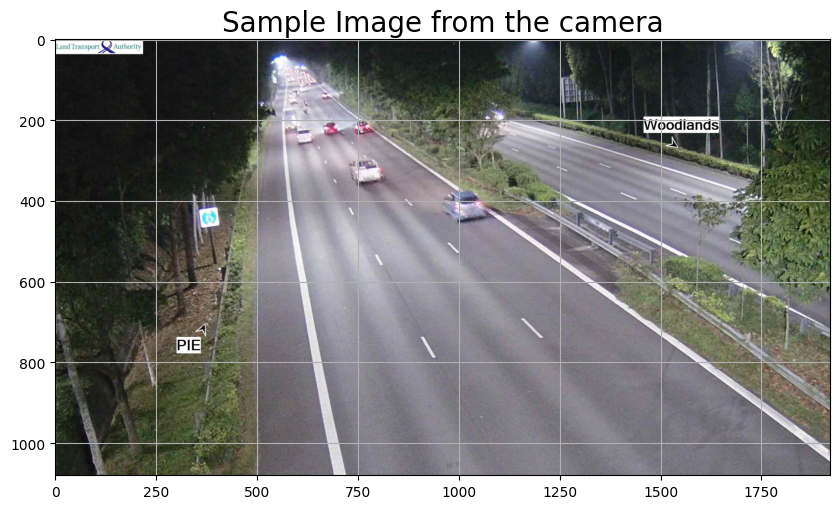

Camera 2705 at 2022-05-24 06:35:00


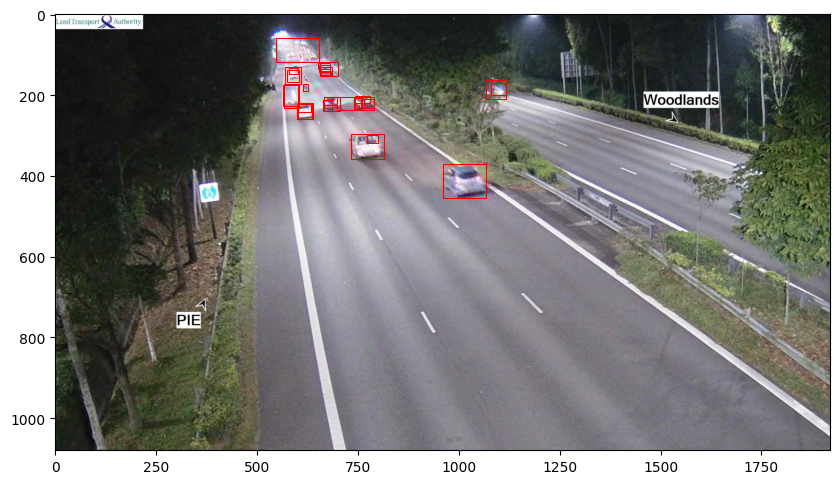

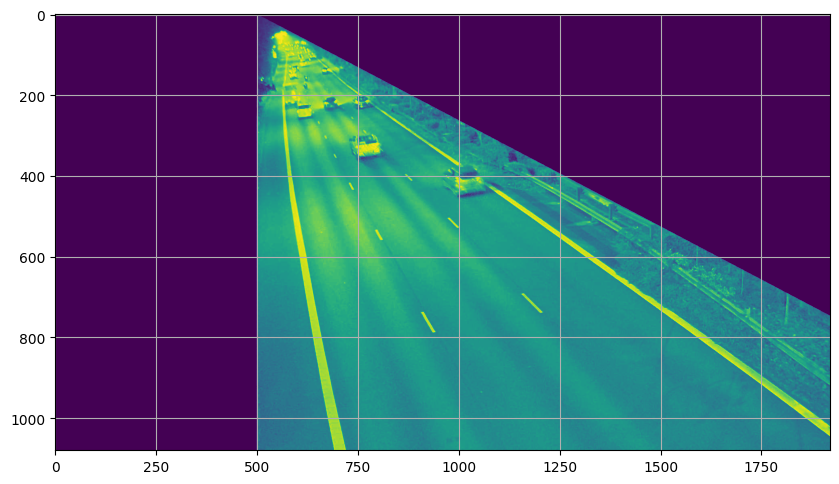

total_area =  3633691
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2705\2705_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2705\b_PIE_2705_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2705_2022-05-25_Fullday.csv
Total of objects in the dataset: 11499
Total of objects that are vehicles in camera 2705 : 9512
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2705\2705_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2705\b_PIE_2705_2022-05-26_Fullday.csv
combined_csv Name :

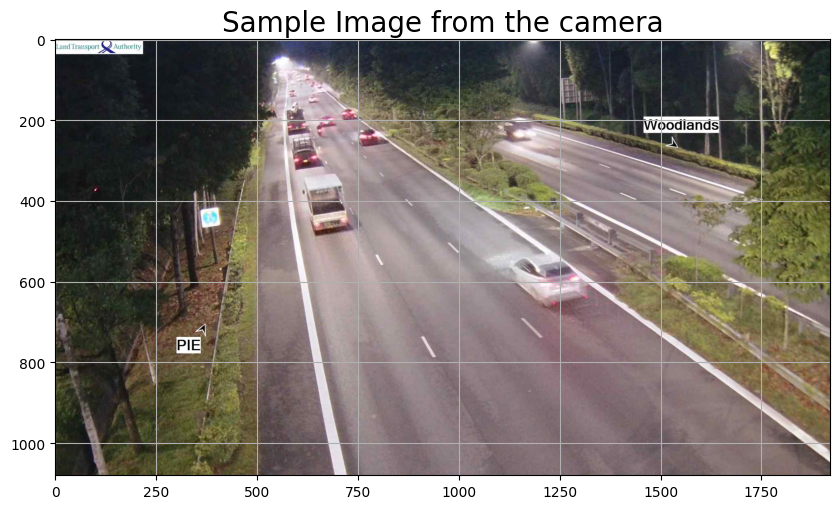

Camera 2705 at 2022-05-26 06:45:00


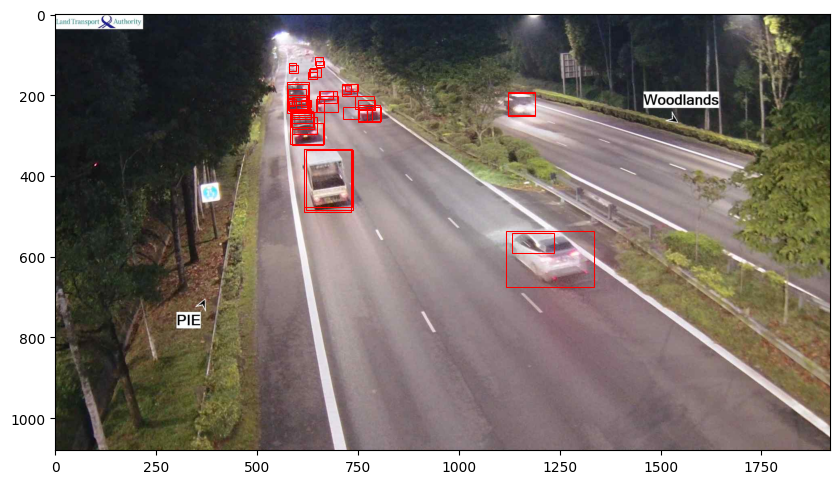

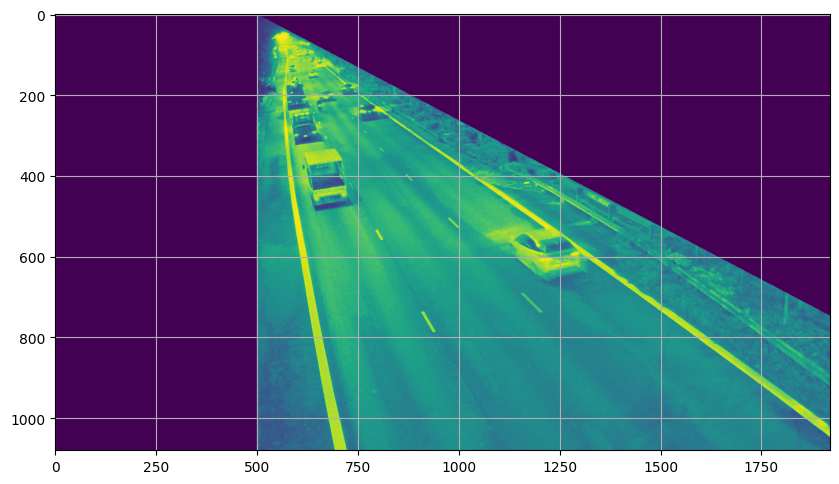

total_area =  3633691
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2705\2705_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2705\b_PIE_2705_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2705_2022-05-27_Fullday.csv
Total of objects in the dataset: 12026
Total of objects that are vehicles in camera 2705 : 9896
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2705\2705_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2705\b_PIE_2705_2022-05-28_Fullday.csv
combined_csv Name :

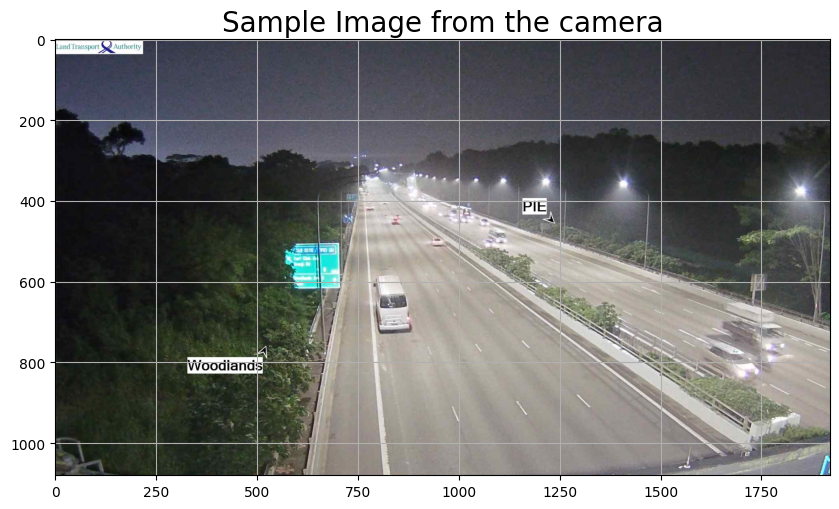

Camera 2706 at 2022-05-24 06:15:00


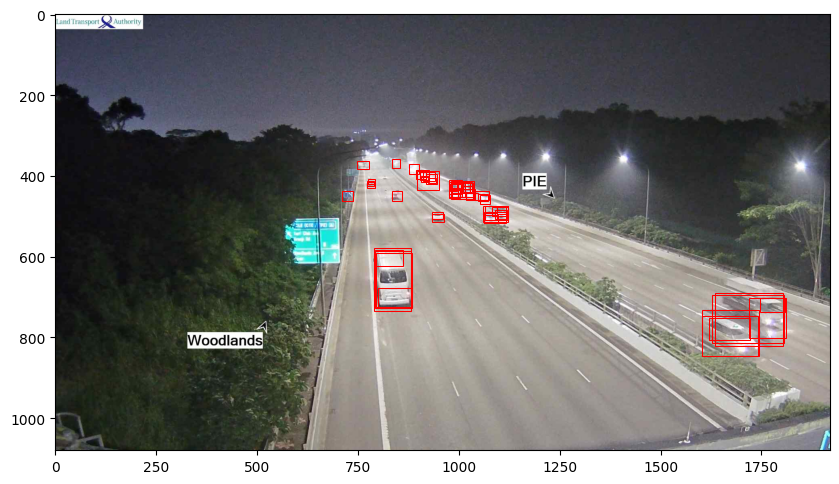

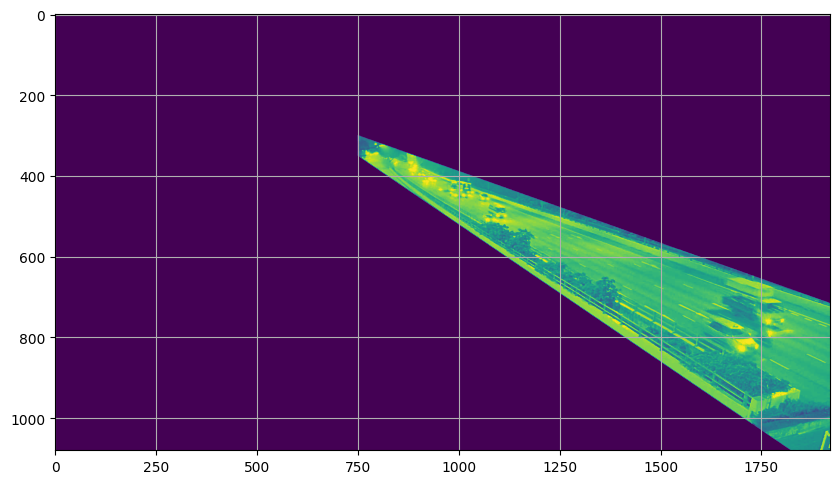

total_area =  3633691
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2706\b_PIE_2706_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2706_2022-05-25_Fullday.csv
Total of objects in the dataset: 17362
Total of objects that are vehicles in camera 2706 : 15242
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2706\b_PIE_2706_2022-05-26_Fullday.csv
combined_csv Nam

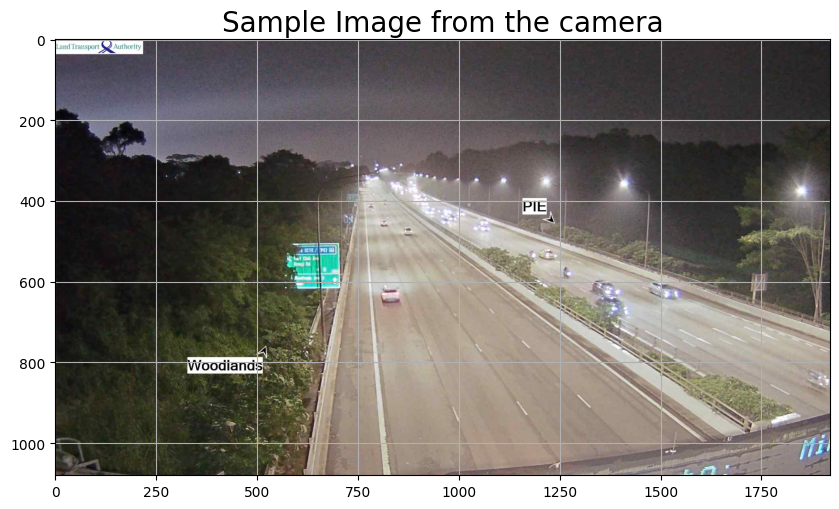

Camera 2706 at 2022-05-26 06:15:00


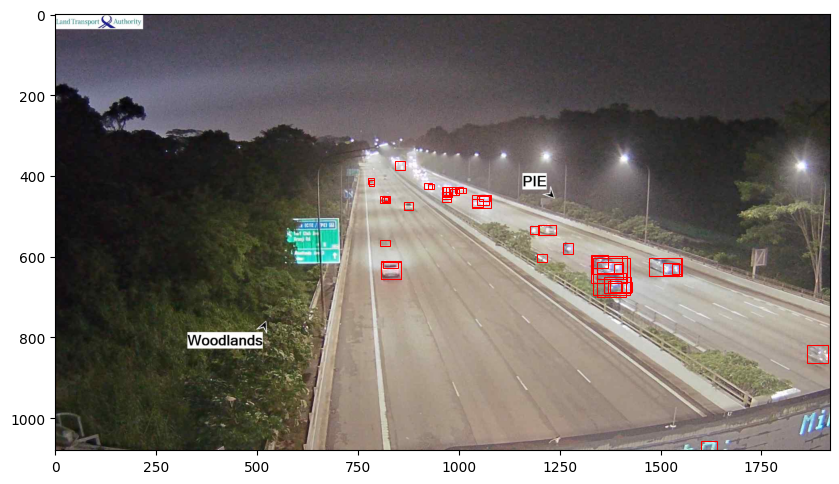

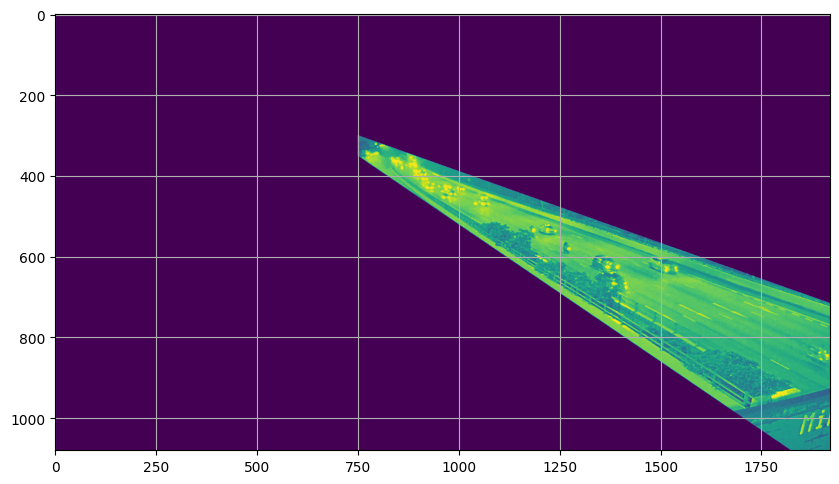

total_area =  3633691
maskedList ::  [False, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2706\b_PIE_2706_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2706_2022-05-27_Fullday.csv
Total of objects in the dataset: 17814
Total of objects that are vehicles in camera 2706 : 15590
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2706\b_PIE_2706_2022-05-28_Fullday.csv
combined_csv Nam

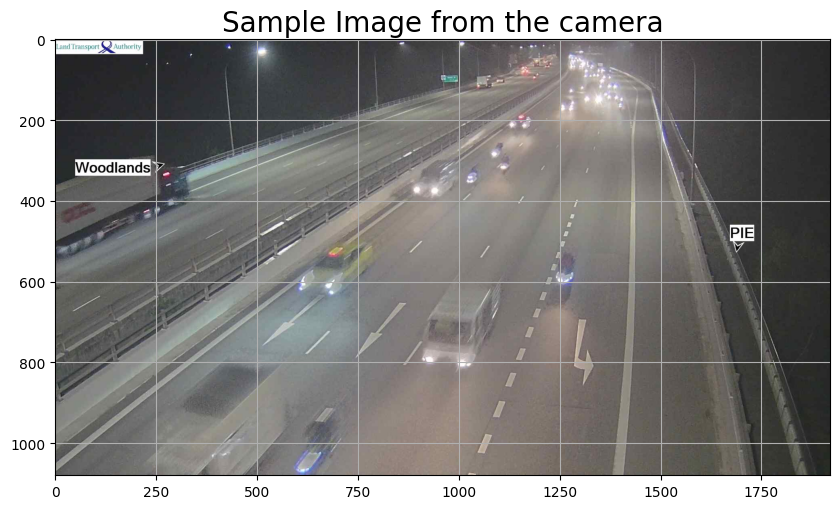

Camera 2707 at 2022-05-24 06:15:00


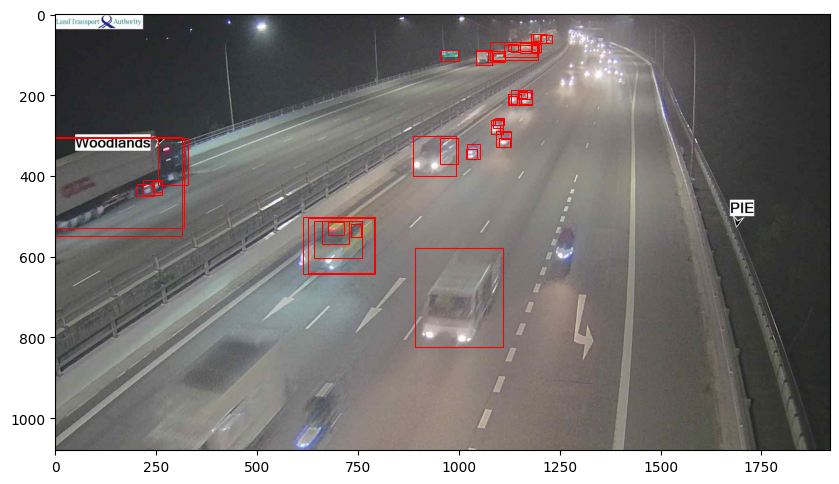

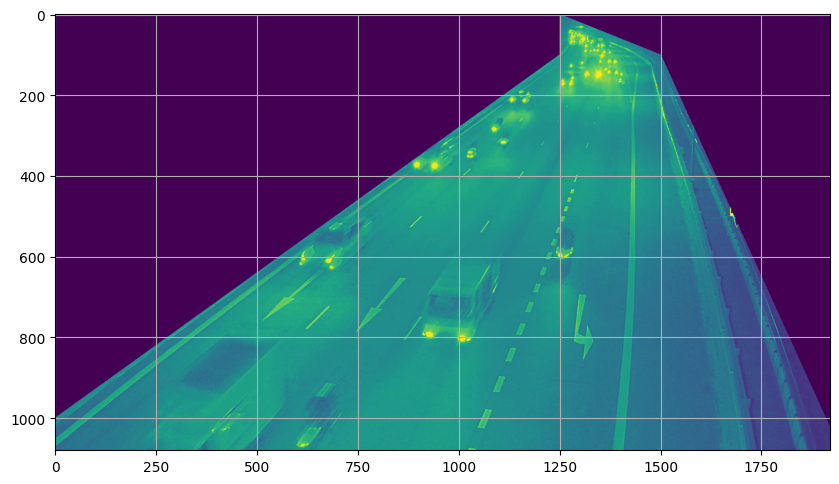

total_area =  3633691
maskedList ::  [False, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2707\b_PIE_2707_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2707_2022-05-25_Fullday.csv
Total of objects in the dataset: 17549
Total of objects that are vehicles in camera 2707 : 15219
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2707\b_PIE_2707_2022-05-26_Fullday.csv
combined_csv Na

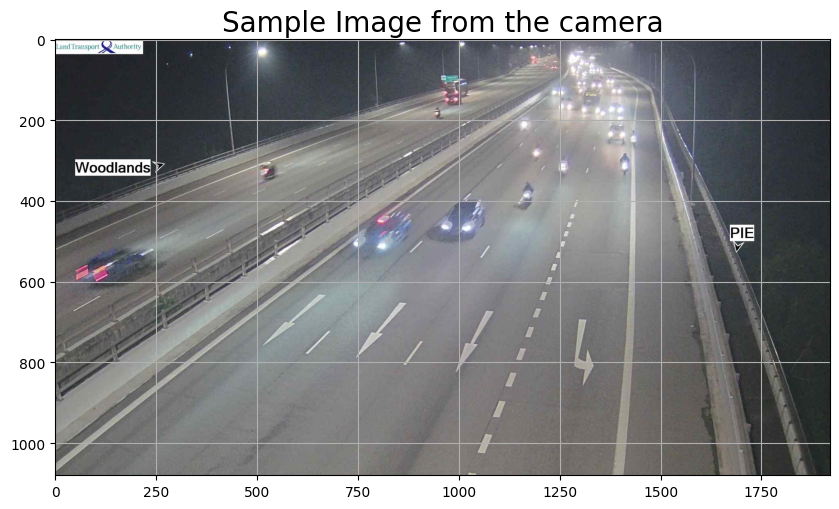

Camera 2707 at 2022-05-26 06:20:00


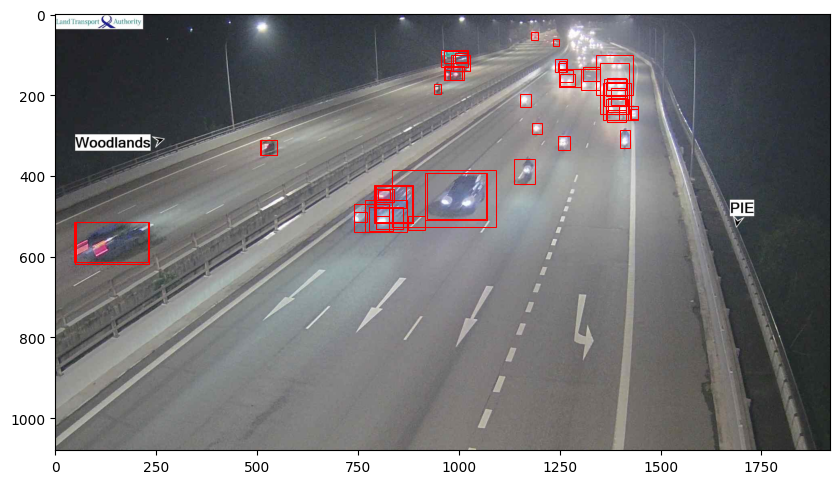

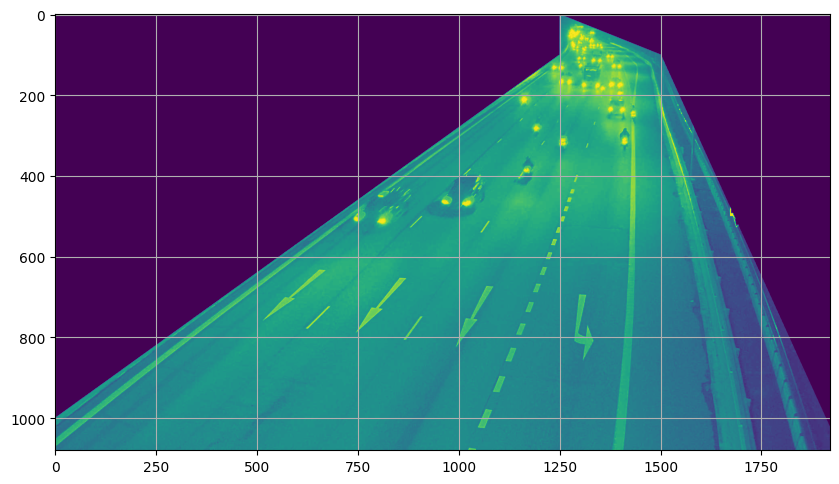

total_area =  3633691
maskedList ::  [False, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2707\b_PIE_2707_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_PIE_2707_2022-05-27_Fullday.csv
Total of objects in the dataset: 18314
Total of objects that are vehicles in camera 2707 : 15725
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_PIE\2707\b_PIE_2707_2022-05-28_Fullday.csv
combined_csv Na

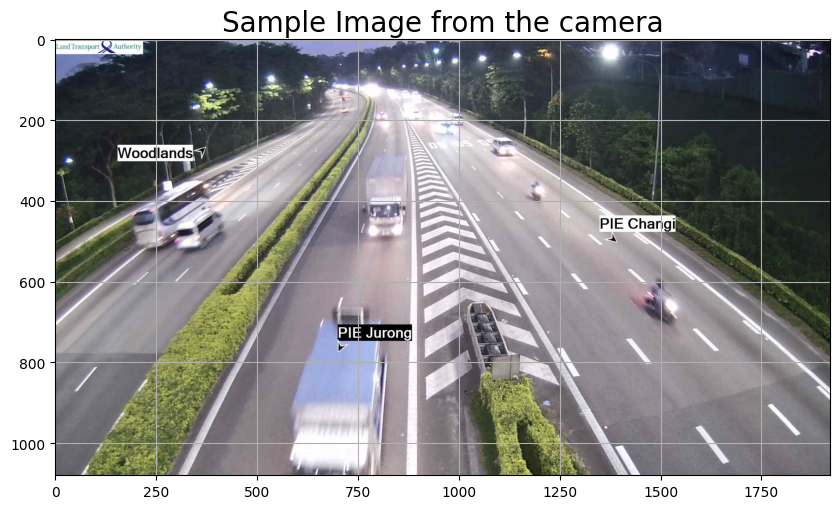

Camera 2703 at 2022-05-24 06:45:00


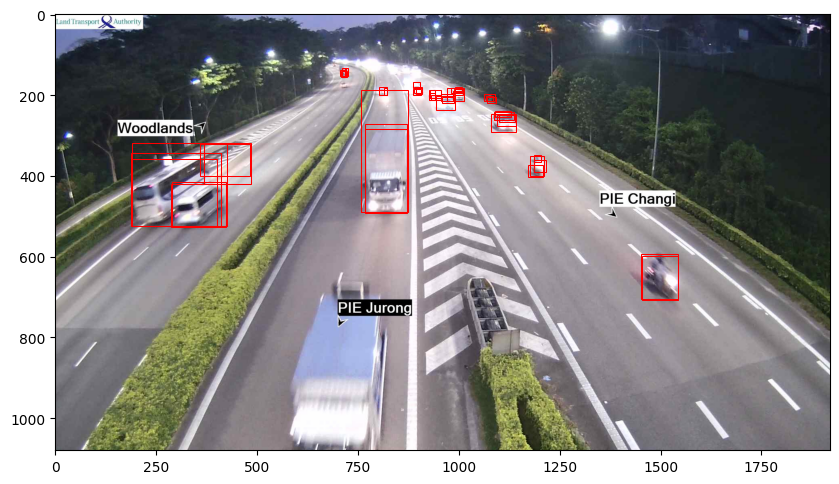

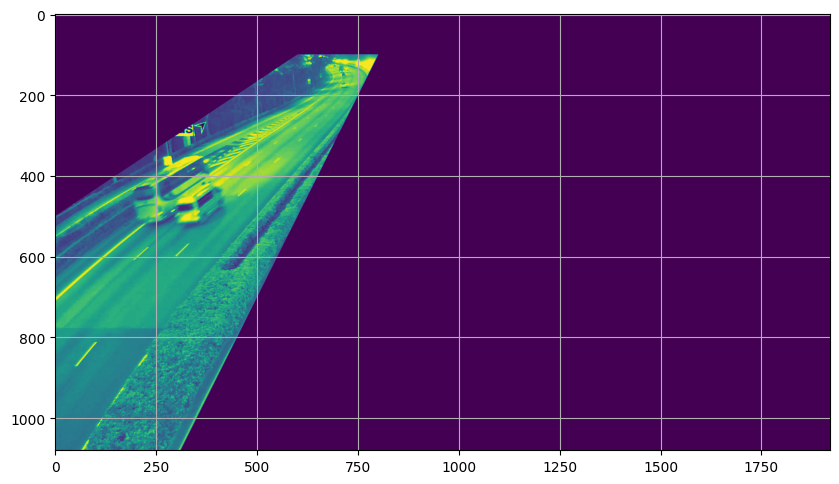

total_area =  3633691
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2703\2703_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2703_2022-05-25_Fullday.csv
Total of objects in the dataset: 14190
Total of objects that are vehicles in camera 2703 : 12182
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2703\2703_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-05-

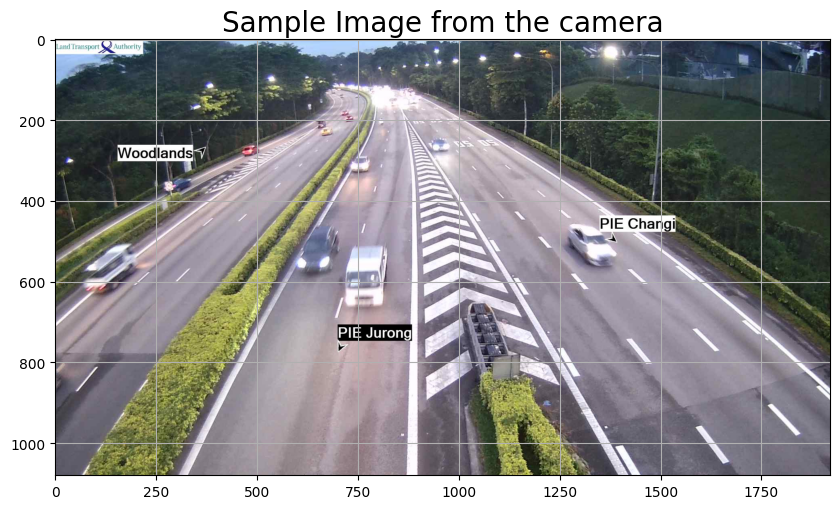

Camera 2703 at 2022-05-26 06:55:00


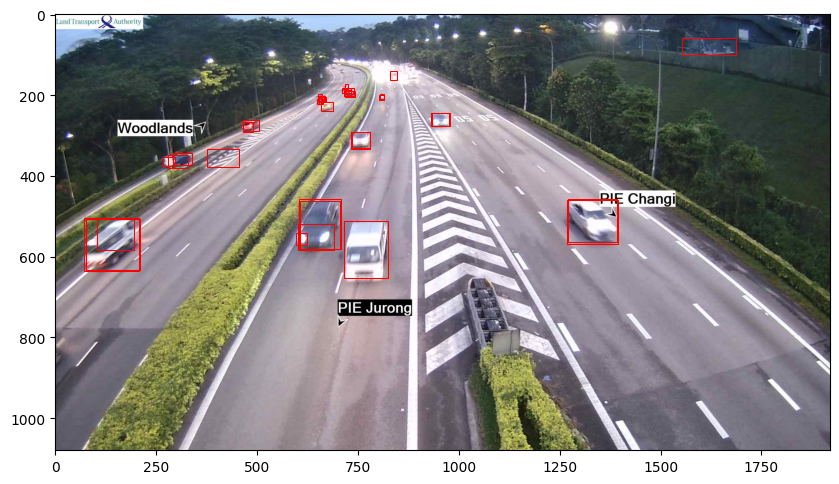

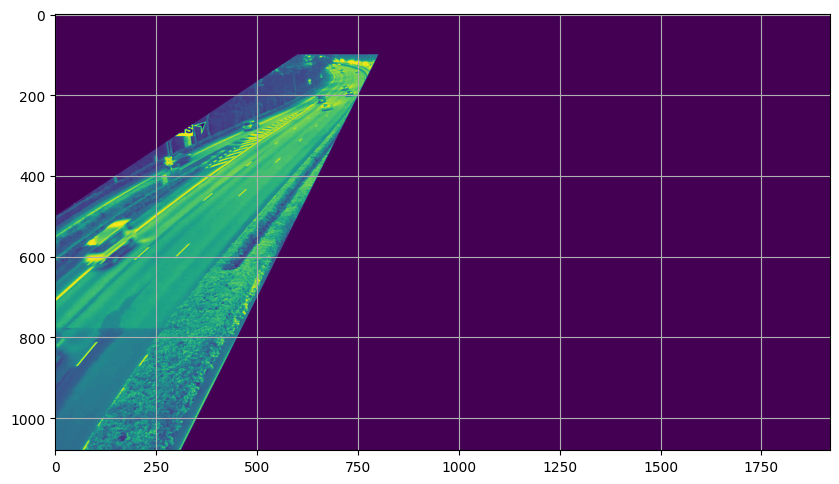

total_area =  3633691
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2703\2703_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2703_2022-05-27_Fullday.csv
Total of objects in the dataset: 15307
Total of objects that are vehicles in camera 2703 : 13063
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2703\2703_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2703\b_Woodlands_2703_2022-05-2

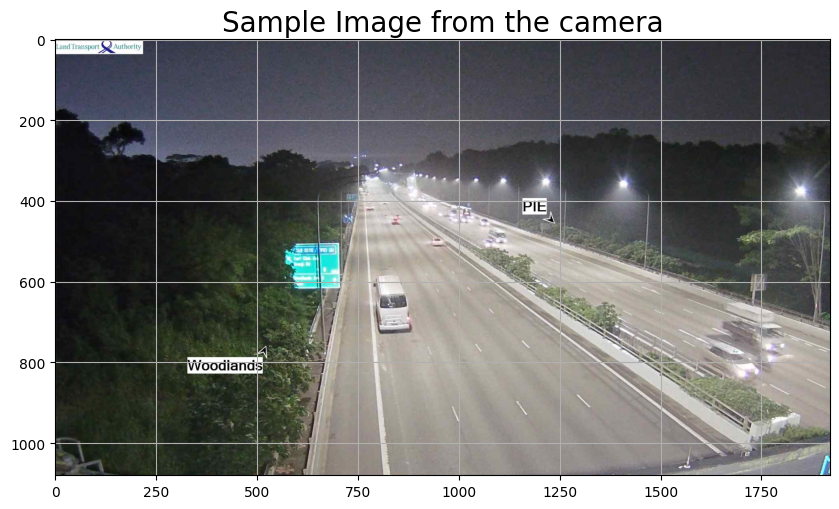

Camera 2706 at 2022-05-24 06:15:00


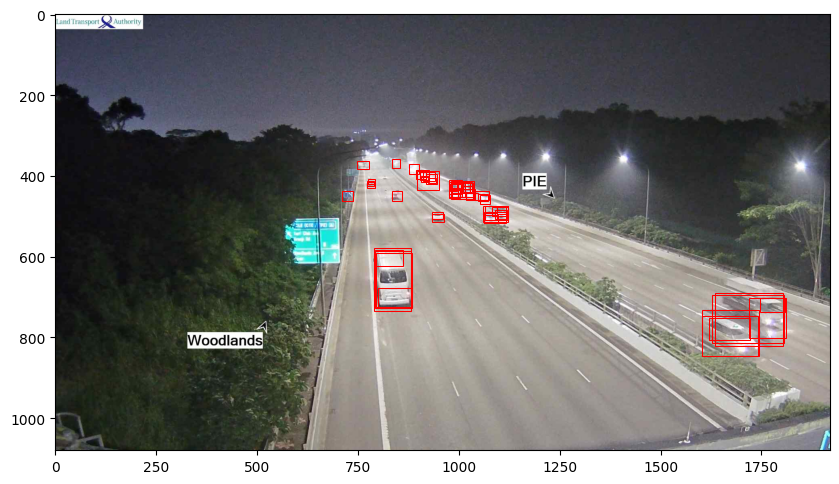

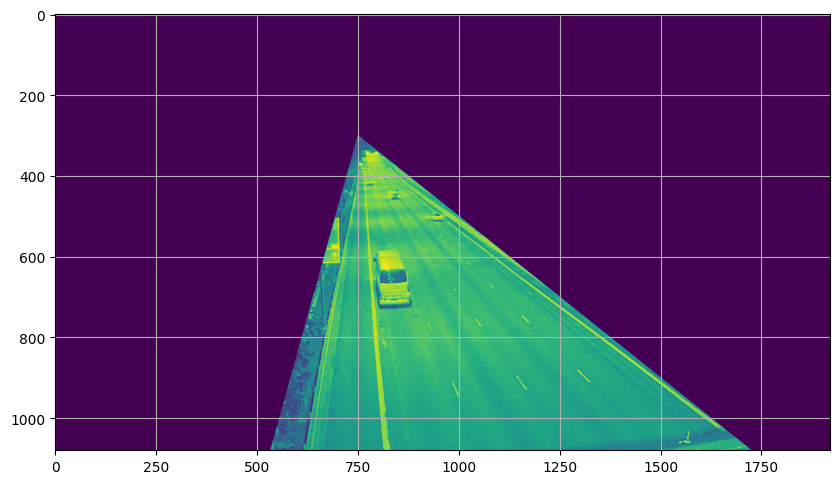

total_area =  3633691
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2706_2022-05-25_Fullday.csv
Total of objects in the dataset: 17362
Total of objects that are vehicles in camera 2706 : 15242
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-05-2

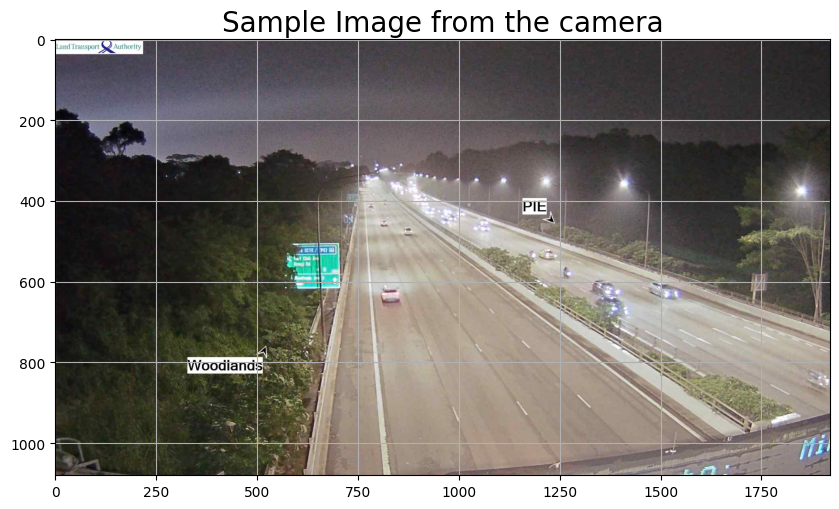

Camera 2706 at 2022-05-26 06:15:00


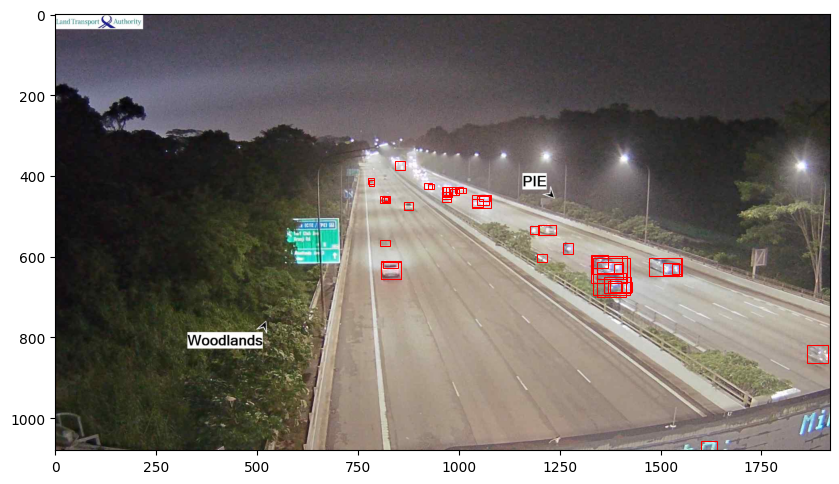

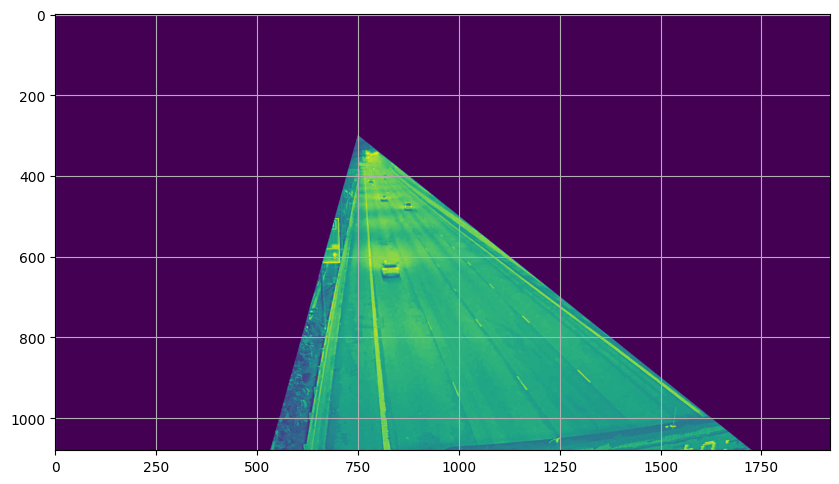

total_area =  3633691
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2706_2022-05-27_Fullday.csv
Total of objects in the dataset: 17814
Total of objects that are vehicles in camera 2706 : 15590
maskedList ::  [False, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2706\2706_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2706\b_Woodlands_2706_2022-05-

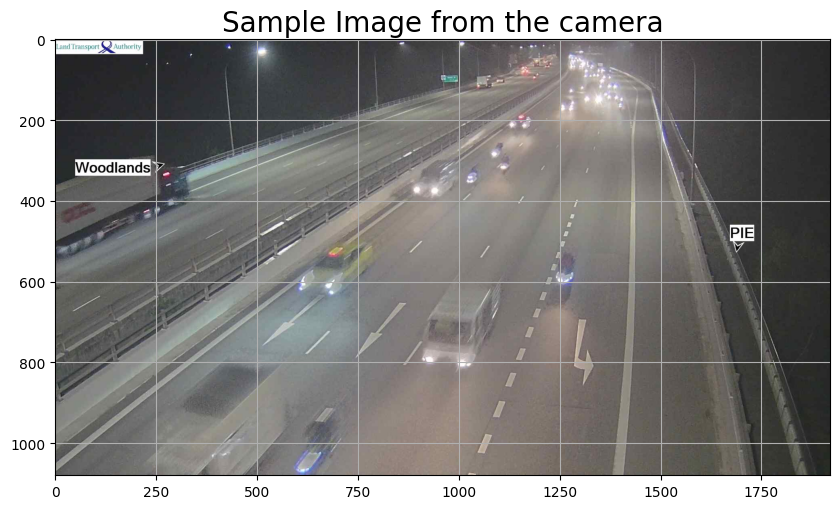

Camera 2707 at 2022-05-24 06:15:00


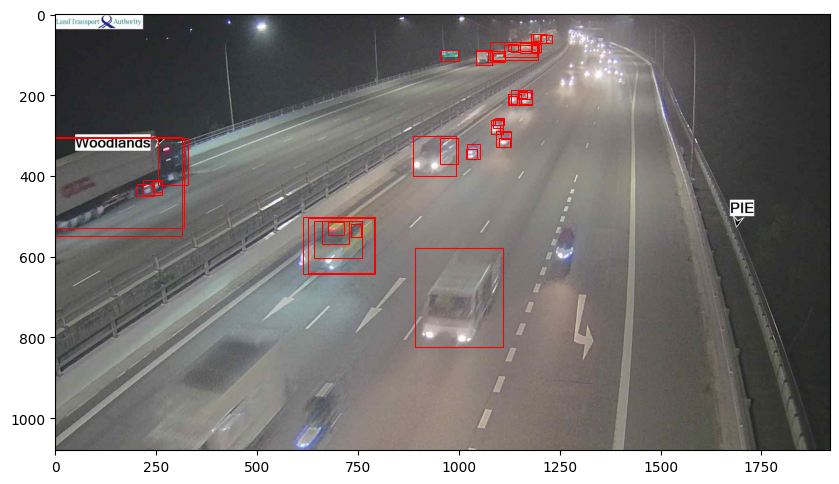

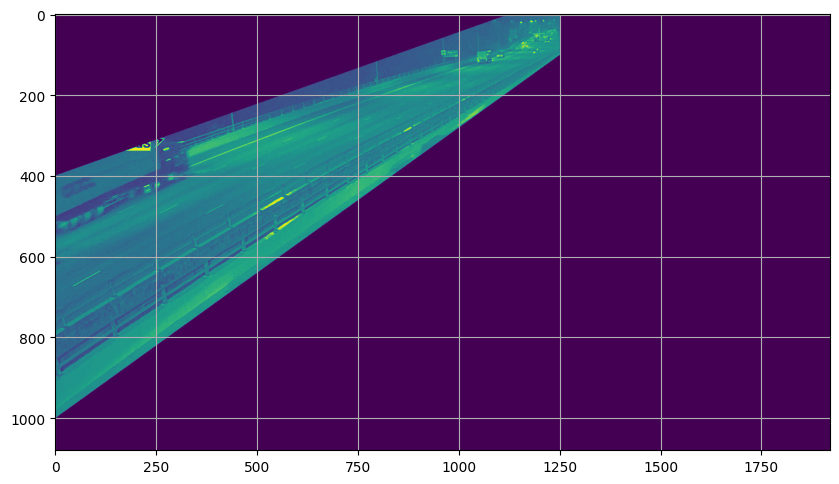

total_area =  3633691
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2707_2022-05-25_Fullday.csv
Total of objects in the dataset: 17549
Total of objects that are vehicles in camera 2707 : 15219
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-05-26

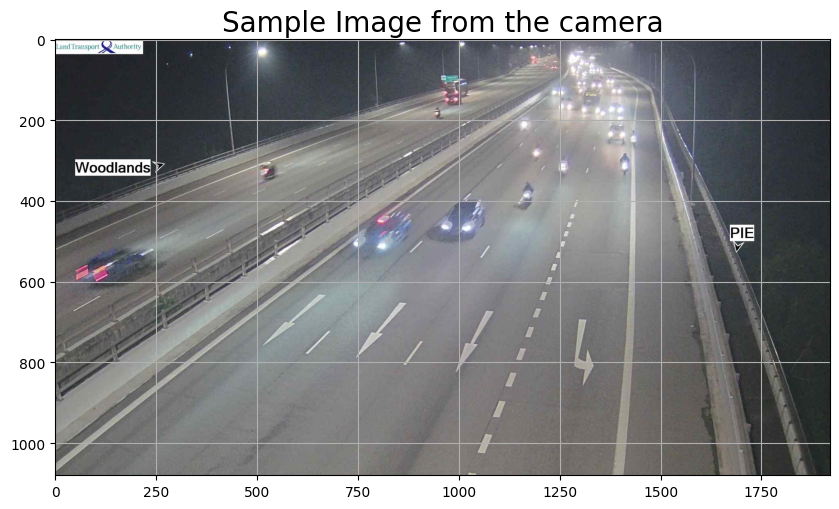

Camera 2707 at 2022-05-26 06:20:00


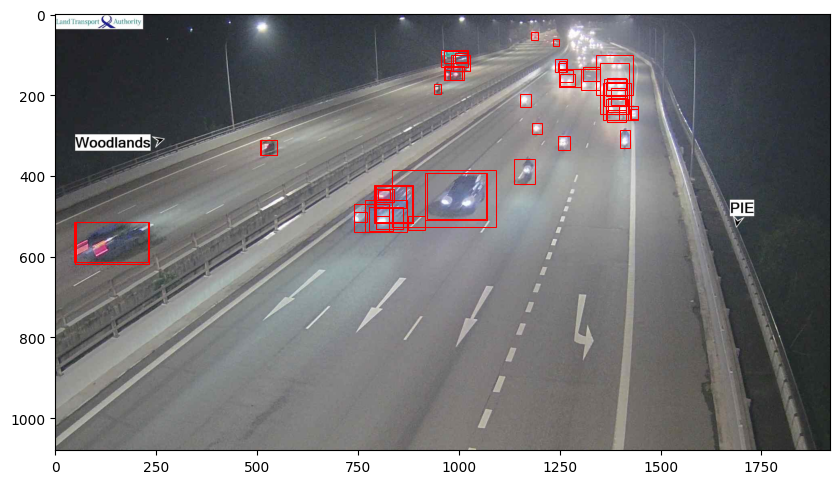

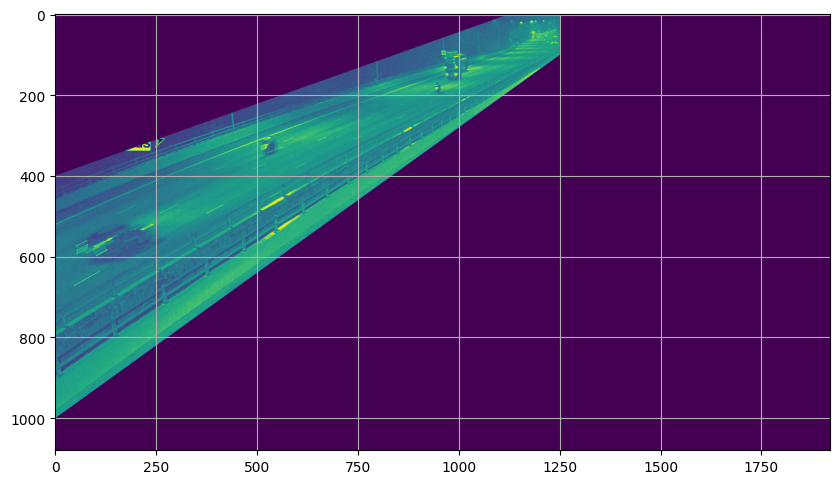

total_area =  3633691
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2707_2022-05-27_Fullday.csv
Total of objects in the dataset: 18314
Total of objects that are vehicles in camera 2707 : 15725
maskedList ::  [True, True]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2707\2707_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2707\b_Woodlands_2707_2022-05-28

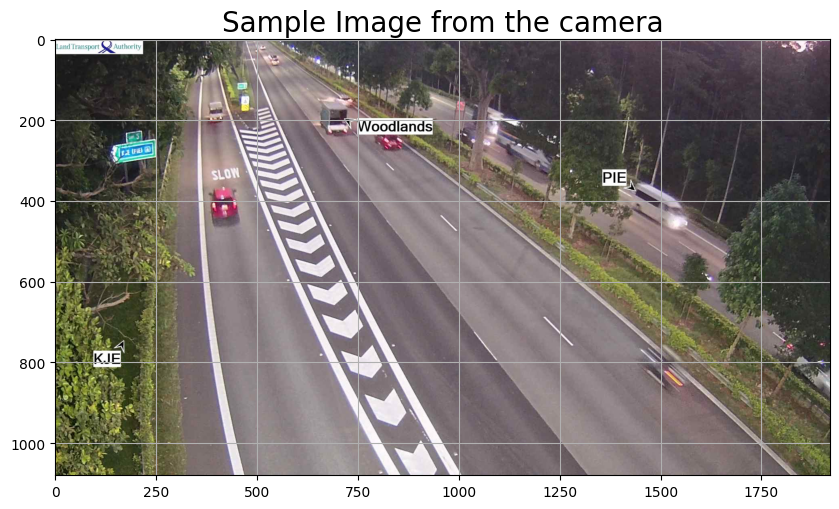

Camera 2708 at 2022-05-24 06:45:00


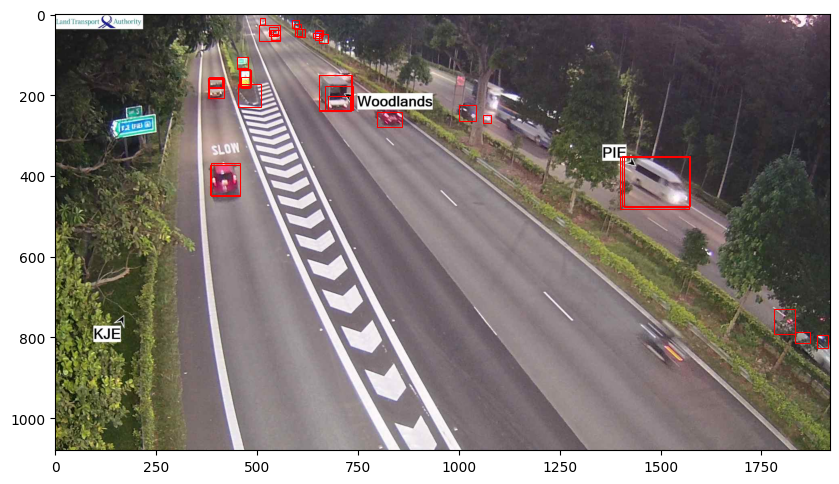

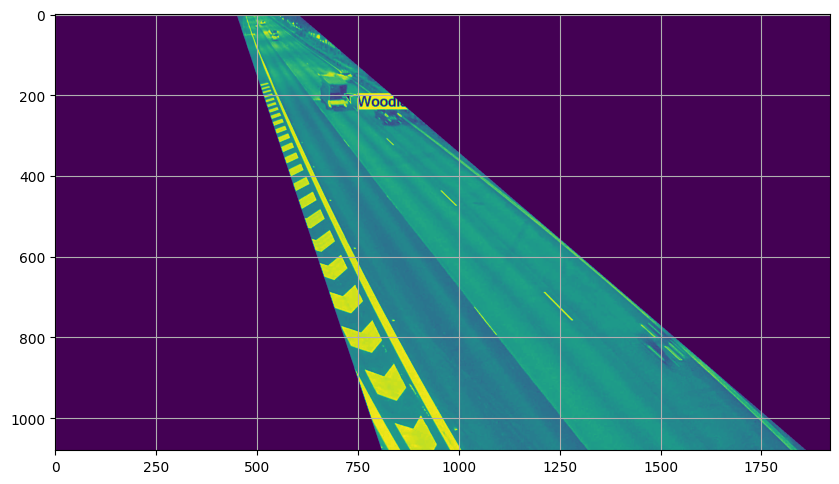

total_area =  3633691
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2708\2708_2022-5-25_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-05-25_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2708_2022-05-25_Fullday.csv
Total of objects in the dataset: 10542
Total of objects that are vehicles in camera 2708 : 8361
maskedList ::  [True, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2708\2708_2022-5-26_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-05-26

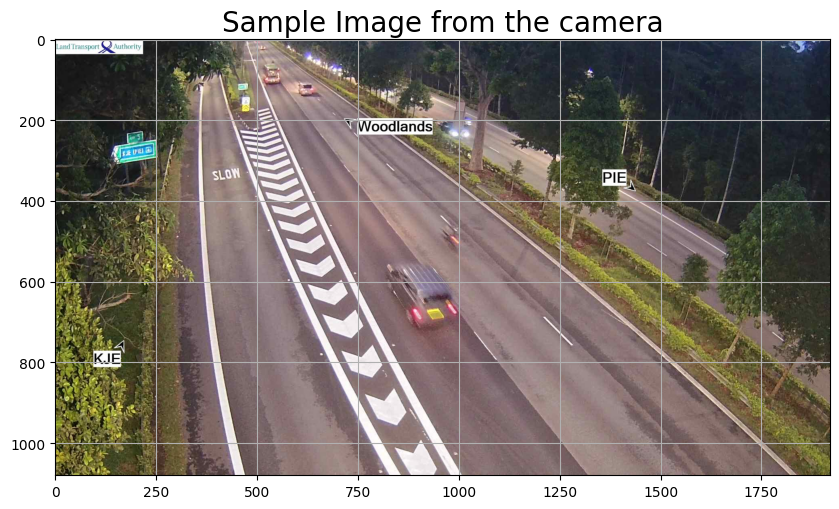

Camera 2708 at 2022-05-26 06:50:00


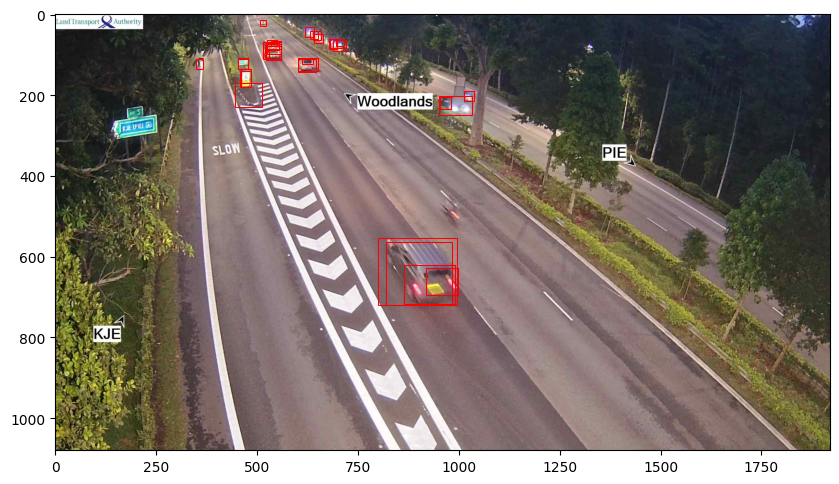

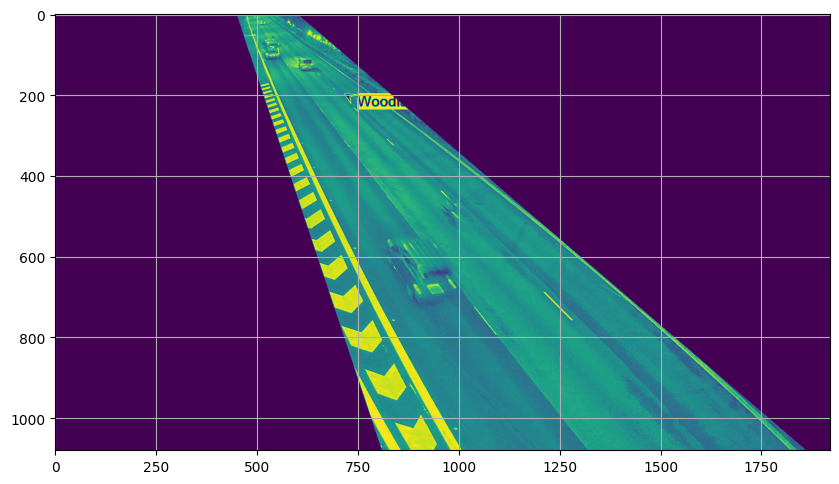

total_area =  3633691
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2708\2708_2022-5-27_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-05-27_Fullday.csv
combined_csv Name ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\output_csv_transformer_test\5\combined_b_Woodlands_2708_2022-05-27_Fullday.csv
Total of objects in the dataset: 10714
Total of objects that are vehicles in camera 2708 : 8249
maskedList ::  [False, False]
cnn_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_cnn_2022\2708\2708_2022-5-28_cnn.csv
google_csv_file ::  C:\Users\Padmapriya\Documents\ML_projects\testenv1\Counting-vehicles-by-direction\input\may_google_2022\b_Woodlands\2708\b_Woodlands_2708_2022-05-

In [84]:
for ROUTE_DIR in unique_route:
    pdf  = coord_df.loc[(coord_df['Route']==ROUTE_DIR)]
    for CAMERA_ID in pdf['Cam_id']:
        print(ROUTE_DIR,CAMERA_ID)
        df  = pdf.loc[(pdf['Route']==ROUTE_DIR) & (pdf['Cam_id']==CAMERA_ID)] 
        xy = df['masking_xy_march 2022'].item()
        xy = list(eval(xy))
        print(xy)

        INPUT_DIR_PATH,GOOGLE_PATH,CNN_PATH,ROUTE_PATH,GOOGLE_CAMERA_PATH,CNN_CAMERA_PATH,OUTPUT_CSV_PATH, OUTPUT_IMG_PATH,MASKED_IMG,BB_IMG= define_path(ROUTE_DIR,CAMERA_ID,GOOGLE_DIR,CNN_DIR,MONTH)
        
        #Input
        google_file_list, cnn_file_list = get_google_cnn_file_list(GOOGLE_CAMERA_PATH)
        #xy = findMaskingCoordinates(coord_df,ROUTE_DIR,CAMERA_ID)

        for i in range(len(google_file_list)):
            cnn_csv_file = os.path.join(CNN_CAMERA_PATH , cnn_file_list[i])
            print("cnn_csv_file :: ", cnn_csv_file)

            google_csv_file = os.path.join(GOOGLE_CAMERA_PATH , google_file_list[i]) 
            print("google_csv_file :: ",google_csv_file)

            ## Yet to fix *************
            combined_csv=os.path.join(OUTPUT_CSV_PATH , "combined_"+google_file_list[i])
            print("combined_csv Name :: ",combined_csv)

            df = read_cnn_csv(cnn_csv_file)
            df['Route'] = ROUTE_DIR
            if(i==0 or i==2):
                img, url = check_img_size(df)
                plot_bounding_boxes(df, img,url,BB_IMG)
                masked_img = create_mask(df, img, xy,url,MASKED_IMG)
                total_area  = find_total_area(masked_img)
                
                maskedList = check_masked_List(df, xy)
                df2 = keep_desired_vehicles(df, maskedList)
                
            else:
                maskedList = check_masked_List(df, xy)
                df2 = keep_desired_vehicles(df, maskedList)
                
                
                combined_df = combined_df.append(df2, ignore_index=True)

In [85]:
combined_df['Route'].unique()

array(['b_PIE', 'b_Woodlands'], dtype=object)

In [86]:
combined_df.columns

Index(['Unnamed: 0', 'Image_id', 'Cam_ID', 'Detection_Class',
       'Detection_Score', 'Timestamp_sg_time', 'URL', 'ymin', 'xmin', 'ymax',
       'xmax', 'Bounding_box_area', 'Proportion_bounding_box_0_100',
       'Segmentation_pixels', 'Route', 'desired', 'ones', 'hour', 'minute'],
      dtype='object')

In [88]:
columns_to_drop = ['Unnamed: 0','URL', 'ymin', 'xmin', 'ymax', 'xmax', 'Bounding_box_area', 
                   'Proportion_bounding_box_0_100','ones','desired','hour','minute']

# Drop the specified columns in-place
combined_df.drop(columns=columns_to_drop, inplace=True)

In [91]:
#columns_to_drop = ['Segmentation_pixels']
#combined_df.drop(columns=columns_to_drop, inplace=True)

combined_df.to_csv('maskrcnn_march_june_vehicle_summary.csv',index=False)

In [72]:
combined_df.to_csv('transformer_march_june_vehicle_summary.csv',index=False)

### Speed summary

In [ ]:
input_file = "regression_input_all_maskrcnn.csv"
output_file = "maskrcnn_march_june_speed_summary.csv"

In [ ]:
output_file = "maskrcnn_march_june_speed_summary.csv"
output_file = "transformer_march_june_speed_summary.csv"

In [ ]:
df = pd.read_csv(input_file)
df = df[(df['X14_Month'] != 2) & (df['X14_Month'] != 7)]


def convert_speed_ms_to_kmh(speed_ms):
    return int(speed_ms * 3.6)

if 'Y_Speed' in df.columns:
    df['Y_Speed'] = df['Y_Speed'].apply(convert_speed_ms_to_kmh)
    
    
df.to_csv(output_file,index=False)

### Calculating Avg speed per hour

In [117]:
output_file = "maskrcnn_march_june_speed_summary.csv"
output_file_avg = "march_june_avg_speed_per_camera.csv"


df = pd.read_csv(output_file)
df = df[(df['X14_Month'] != 2) & (df['X14_Month'] != 7)]


def split_time(df):
    df['Timestamp'] = pd.to_datetime(df['Timestamp']) 
    df['hour'] = df['Timestamp'].dt.hour
    df['day_type'] = df['Timestamp'].dt.dayofweek.apply(lambda x: 'weekday' if x < 5 else 'weekend')

split_time(df)

avg_speed_df = df.groupby(['Route', 'Camera_id', 'hour','day_type'], as_index=False)['Y_Speed'].mean()

# Rename the 'Y_Speed' column to 'avg_speed'
avg_speed_df = avg_speed_df.rename(columns={'Y_Speed': 'avg_speed'})

# Display the resulting dataframe
avg_speed_df.to_csv(output_file_avg,index=False)

In [118]:
output_file = "maskrcnn_march_june_speed_summary.csv"
output_file_avg = "march_june_avg_speed_per_route.csv"


df = pd.read_csv(output_file)
df = df[(df['X14_Month'] != 2) & (df['X14_Month'] != 7)]


def split_time(df):
    df['Timestamp'] = pd.to_datetime(df['Timestamp']) 
    df['hour'] = df['Timestamp'].dt.hour
    
    df['day_type'] = df['Timestamp'].dt.dayofweek.apply(lambda x: 'weekday' if x < 5 else 'weekend')

split_time(df)

avg_speed_df = df.groupby(['Route', 'hour','day_type'], as_index=False)['Y_Speed'].mean()

# Rename the 'Y_Speed' column to 'avg_speed'
avg_speed_df = avg_speed_df.rename(columns={'Y_Speed': 'avg_speed'})

# Display the resulting dataframe
avg_speed_df.to_csv(output_file_avg,index=False)

In [119]:
avg_speed_df

,Route,hour,day_type,avg_speed
0,b_PIE,4,weekday,86.158333
1,b_PIE,4,weekend,86.791667
2,b_PIE,5,weekday,85.170833
3,b_PIE,5,weekend,85.597222
4,b_PIE,6,weekday,79.001389
...,...,...,...,...
75,b_Woodlands,21,weekend,77.052083
76,b_Woodlands,22,weekday,78.327083
77,b_Woodlands,22,weekend,78.302083
78,b_Woodlands,23,weekday,81.395455
